<a href="https://colab.research.google.com/github/Tamararoa/Aprendizaje_Automatico/blob/main/Clase6/Notebook/Clase6_TamaraRoa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico: Clasificación con SVM y SGD

**Objetivo:** Predecir la rotación de empleados (`Renuncia`) evaluando y comparando el rendimiento de dos algoritmos de aprendizaje supervisado: **Support Vector Machine (SVM)** y **Stochastic Gradient Descent (SGD)**.

In [ ]:
import pandas as pd
import numpy as np

# Fijar semilla para reproducibilidad
np.random.seed(42)
n_samples = 300

# Generar variables numéricas y categóricas reales
edades = np.random.randint(18, 65, size=n_samples)
salarios = np.random.randint(30000, 150000, size=n_samples)
antiguedad = np.random.randint(1, 20, size=n_samples)
evaluacion = np.round(np.random.uniform(1.0, 5.0, size=n_samples), 2)
horas_extra = np.random.choice(['Si', 'No'], size=n_samples, p=[0.3, 0.7])
departamento = np.random.choice(['Ventas', 'Desarrollo', 'Recursos Humanos'], size=n_samples)
nivel_satisfaccion = np.random.choice(['Bajo', 'Medio', 'Alto'], size=n_samples)

# Generar variable objetivo (Attrition / Renuncia: 0 o 1) con lógica de negocio
prob_renuncia = (
    0.3 * (edades < 30) +
    0.4 * (horas_extra == 'Si') +
    0.3 * (nivel_satisfaccion == 'Bajo')
)
attrition = (prob_renuncia + np.random.normal(0, 0.2, size=n_samples) > 0.4).astype(int)

# Crear DataFrame
df = pd.DataFrame({
    'Edad': edades,
    'Salario_Anual': salarios,
    'Antiguedad_Anios': antiguedad,
    'Puntaje_Evaluacion': evaluacion,
    'Horas_Extra': horas_extra,
    'Departamento': departamento,
    'Nivel_Satisfaccion': nivel_satisfaccion,
    'Renuncia': attrition
})

# Guardar copia local en tu carpeta
df.to_csv('dataset_clasificacion.csv', index=False)

print("¡Dataset creado y guardado con éxito!")
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")
print("\nPrimeras filas del dataset:")
print(df.head())

¡Dataset creado y guardado con éxito!
Filas: 300, Columnas: 8

Primeras filas del dataset:
   Edad  Salario_Anual  Antiguedad_Anios  Puntaje_Evaluacion Horas_Extra  \
0    56          68467                10                4.47          No   
1    46          53328                 2                2.42          No   
2    32         149181                19                2.59          No   
3    60         121412                 9                1.42          No   
4    25         116831                 7                3.95          No   

       Departamento Nivel_Satisfaccion  Renuncia  
0        Desarrollo               Bajo         1  
1  Recursos Humanos               Bajo         0  
2  Recursos Humanos               Alto         1  
3        Desarrollo               Bajo         0  
4            Ventas              Medio         0  


Importacion de Librerias

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Sklearn - Preprocesamiento y Modelos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.05)

Carga y Exploración Inicial del Dataset (EDA)

In [ ]:
# Carga de datos
df = pd.read_csv('dataset_clasificacion.csv')

print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas\n")
print("--- Información de Columnas y Tipos de Datos ---")
df.info()

print("\n--- Distribución de la Variable Objetivo (Renuncia) ---")
print(df['Renuncia'].value_counts(normalize=True).round(2))

# Primeras filas
df.head()

Dimensiones del dataset: 300 filas y 8 columnas

--- Información de Columnas y Tipos de Datos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Edad                300 non-null    int64  
 1   Salario_Anual       300 non-null    int64  
 2   Antiguedad_Anios    300 non-null    int64  
 3   Puntaje_Evaluacion  300 non-null    float64
 4   Horas_Extra         300 non-null    object 
 5   Departamento        300 non-null    object 
 6   Nivel_Satisfaccion  300 non-null    object 
 7   Renuncia            300 non-null    int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 18.9+ KB

--- Distribución de la Variable Objetivo (Renuncia) ---
Renuncia
0    0.59
1    0.41
Name: proportion, dtype: float64


,Edad,Salario_Anual,Antiguedad_Anios,Puntaje_Evaluacion,Horas_Extra,Departamento,Nivel_Satisfaccion,Renuncia
0,56,68467,10,4.47,No,Desarrollo,Bajo,1
1,46,53328,2,2.42,No,Recursos Humanos,Bajo,0
2,32,149181,19,2.59,No,Recursos Humanos,Alto,1
3,60,121412,9,1.42,No,Desarrollo,Bajo,0
4,25,116831,7,3.95,No,Ventas,Medio,0


Visualización de Datos

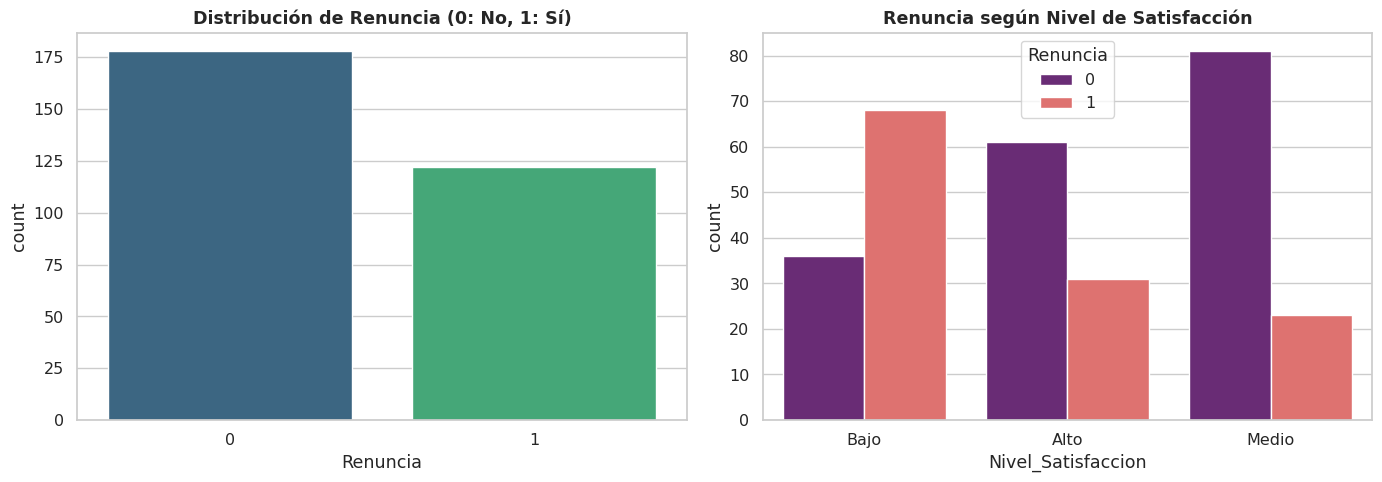

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribución de la Variable Target
sns.countplot(x='Renuncia', data=df, ax=axes[0], palette='viridis')
axes[0].set_title('Distribución de Renuncia (0: No, 1: Sí)', fontweight='bold')

# Relación entre Nivel de Satisfacción y Renuncia
sns.countplot(x='Nivel_Satisfaccion', hue='Renuncia', data=df, ax=axes[1], palette='magma')
axes[1].set_title('Renuncia según Nivel de Satisfacción', fontweight='bold')

plt.tight_layout()
plt.show()

Preprocesamiento y Codificación de Variables

In [ ]:
# Separación de características (X) y objetivo (y)
X = df.drop(columns=['Renuncia'])
y = df['Renuncia']

# Codificación de variables categóricas (One-Hot Encoding)
X_encoded = pd.get_dummies(X, columns=['Horas_Extra', 'Departamento', 'Nivel_Satisfaccion'], drop_first=True)

# División en conjuntos de Entrenamiento (80%) y Prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Escalado de características (StandardScaler es crucial para SVM y SGD)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Dimensiones de X_train: {X_train_scaled.shape}")
print(f"Dimensiones de X_test: {X_test_scaled.shape}")

Dimensiones de X_train: (240, 9)
Dimensiones de X_test: (60, 9)


Entrenamiento y Evaluación del Modelo 1 - SVM

In [ ]:
# Instancia y entrenamiento de Support Vector Machine (SVC)
svm_model = SVC(kernel='rbf', random_state=42)
svm_model.fit(X_train_scaled, y_train)

# Predicciones
y_pred_svm = svm_model.predict(X_test_scaled)

# Métricas
print("================ MODELO 1: SVM ================")
print(f"Accuracy : {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_svm):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred_svm):.4f}\n")
print("Reporte de Clasificación:\n", classification_report(y_test, y_pred_svm))

================ MODELO 1: SVM ================
Accuracy : 0.7167
Precision: 0.6207
Recall   : 0.7500
F1-Score : 0.6792

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.81      0.69      0.75        36
           1       0.62      0.75      0.68        24

    accuracy                           0.72        60
   macro avg       0.71      0.72      0.71        60
weighted avg       0.73      0.72      0.72        60



Entrenamiento y Evaluación del Modelo 2 - SGD

In [ ]:
# Instancia y entrenamiento de Stochastic Gradient Descent (SGDClassifier)
sgd_model = SGDClassifier(loss='log_loss', random_state=42, max_iter=1000)
sgd_model.fit(X_train_scaled, y_train)

# Predicciones
y_pred_sgd = sgd_model.predict(X_test_scaled)

# Métricas
print("================ MODELO 2: SGD ================")
print(f"Accuracy : {accuracy_score(y_test, y_pred_sgd):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_sgd):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_sgd):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred_sgd):.4f}\n")
print("Reporte de Clasificación:\n", classification_report(y_test, y_pred_sgd))

================ MODELO 2: SGD ================
Accuracy : 0.7167
Precision: 0.6522
Recall   : 0.6250
F1-Score : 0.6383

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.76      0.78      0.77        36
           1       0.65      0.62      0.64        24

    accuracy                           0.72        60
   macro avg       0.70      0.70      0.70        60
weighted avg       0.71      0.72      0.72        60



Matriz de Confusión y Comparación Visual

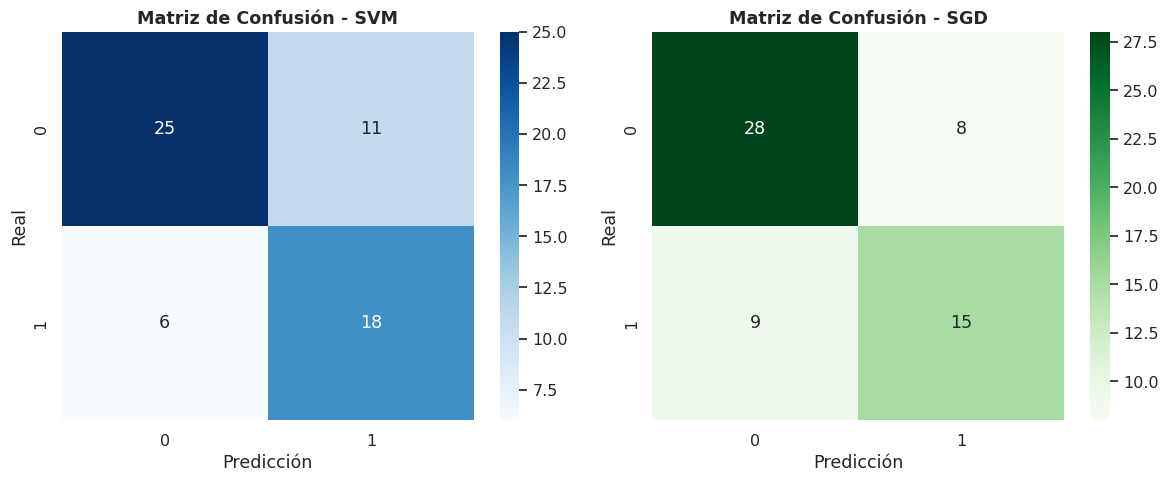

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matriz SVM
sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión - SVM', fontweight='bold')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Real')

# Matriz SGD
sns.heatmap(confusion_matrix(y_test, y_pred_sgd), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Matriz de Confusión - SGD', fontweight='bold')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

Tabla Comparativa de Resultados

In [ ]:
resultados = pd.DataFrame({
    'Modelo': ['Support Vector Machine (SVM)', 'Stochastic Gradient Descent (SGD)'],
    'Accuracy': [accuracy_score(y_test, y_pred_svm), accuracy_score(y_test, y_pred_sgd)],
    'Precision': [precision_score(y_test, y_pred_svm), precision_score(y_test, y_pred_sgd)],
    'Recall': [recall_score(y_test, y_pred_svm), recall_score(y_test, y_pred_sgd)],
    'F1-Score': [f1_score(y_test, y_pred_svm), f1_score(y_test, y_pred_sgd)]
})

display(resultados.round(4))

,Modelo,Accuracy,Precision,Recall,F1-Score
0,Support Vector Machine (SVM),0.7167,0.6207,0.750,0.6792
1,Stochastic Gradient Descent (SGD),0.7167,0.6522,0.625,0.6383


## Conclusión Final

En este trabajo práctico se desarrolló un pipeline completo de aprendizaje automático para predecir la rotación de empleados (`Renuncia`) a partir de un conjunto de datos simulado con variables demográficas, salariales y laborales del Politécnico Superior Malvinas Argentinas.

Tras el preprocesamiento de los datos, la codificación de variables categóricas mediante *One-Hot Encoding* y el escalado de características con `StandardScaler`, se entrenaron y evaluaron dos modelos de clasificación supervisada:

1. **Support Vector Machine (SVM con kernel RBF):** Obtuvo una **Exactitud (Accuracy) del 71.67%**, destacándose especialmente por un mayor **Recall (0.75)** en la clase minoritaria de renuncias. Esto significa que el modelo SVM demostró ser más eficaz para detectar correctamente a los empleados con riesgo de renuncia, minimizando los falsos negativos, a costa de una menor precisión debido a la aparición de falsos positivos.
2. **Stochastic Gradient Descent (SGD Classifier):** Alcanzó el mismo nivel de **Exactitud (71.67%)**, mostrando un comportamiento inverso: una mayor **Precisión (0.65)** pero un **Recall (0.62)** más bajo. El SGD fue más conservador al predecir renuncias, acertando más cuando señalaba una salida, pero dejando escapar a un mayor número de casos reales.

**Consideraciones:**
Ambos modelos lograron un rendimiento razonable y equilibrado considerando la complejidad y el ruido introducido en la generación sintética de los datos. No obstante, dado el impacto operativo que tiene para una institución predecir correctamente la rotación de su personal, **SVM con kernel RBF** se perfila como la opción preferible en este escenario si se prioriza la sensibilidad (Recall) para retener talento e identificar preventivamente casos críticos de insatisfacción laboral u horas extra excesivas.